In [1]:
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import ExtraTreesRegressor, HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

In [2]:
data_path = Path("sales_data.csv")
if not data_path.exists():
    data_path = Path("sales_data(1).csv")

if not data_path.exists():
    raise FileNotFoundError("Put sales_data.csv in the same folder as this notebook.")

df = pd.read_csv(data_path)
df.columns = df.columns.str.lower().str.replace(" ", "_")
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df = df.dropna().drop_duplicates()
df = df.sort_values("date").reset_index(drop=True)

df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month
df["day"] = df["date"].dt.day
df["dayofweek"] = df["date"].dt.dayofweek

print("Dataset file:", data_path)
print("Rows and columns:", df.shape)
print("Date range:", df["date"].min().date(), "to", df["date"].max().date())
df.head()

Dataset file: sales_data.csv
Rows and columns: (76000, 20)
Date range: 2022-01-01 to 2024-01-30


,date,store_id,product_id,category,region,inventory_level,units_sold,units_ordered,price,discount,weather_condition,promotion,competitor_pricing,seasonality,epidemic,demand,year,month,day,dayofweek
0,2022-01-01,S001,P0001,Electronics,North,195,102,252,72.72,5,Snowy,0,85.73,Winter,0,115,2022,1,1,5
1,2022-01-01,S004,P0013,Groceries,West,136,104,385,20.24,10,Snowy,0,18.90,Winter,0,110,2022,1,1,5
2,2022-01-01,S004,P0012,Electronics,West,111,111,113,118.15,0,Snowy,0,133.46,Winter,0,103,2022,1,1,5
3,2022-01-01,S004,P0011,Clothing,West,195,60,293,52.89,0,Snowy,0,62.29,Winter,0,61,2022,1,1,5
4,2022-01-01,S004,P0010,Groceries,West,223,120,597,30.02,0,Snowy,0,29.15,Winter,0,128,2022,1,1,5


In [3]:
target = "demand"
drop_cols = ["demand", "units_sold", "units_ordered", "date"]

categorical = ["store_id", "product_id", "category", "region", "weather_condition", "seasonality"]
numeric = [c for c in df.columns if c not in drop_cols + categorical]

print("Target:", target)
print("Categorical features:", categorical)
print("Numeric features:", numeric)

Target: demand
Categorical features: ['store_id', 'product_id', 'category', 'region', 'weather_condition', 'seasonality']
Numeric features: ['inventory_level', 'price', 'discount', 'promotion', 'competitor_pricing', 'epidemic', 'year', 'month', 'day', 'dayofweek']


In [4]:
split_date = pd.Timestamp("2023-09-01")

train = df[df["date"] < split_date].copy()
test = df[df["date"] >= split_date].copy()

X_train = train.drop(columns=drop_cols)
y_train = train[target]
X_test = test.drop(columns=drop_cols)
y_test = test[target]

print("Train rows:", len(train), "| from", train["date"].min().date(), "to", train["date"].max().date())
print("Test rows :", len(test), "| from", test["date"].min().date(), "to", test["date"].max().date())

Train rows: 60800 | from 2022-01-01 to 2023-08-31
Test rows : 15200 | from 2023-09-01 to 2024-01-30


In [5]:
preprocess = ColumnTransformer([
    ("num", StandardScaler(), numeric),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical),
])

models = {
    "Baseline (mean)": DummyRegressor(strategy="mean"),
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(min_samples_leaf=5, random_state=42),
    "Extra Trees": ExtraTreesRegressor(n_estimators=60, min_samples_leaf=2, random_state=42, n_jobs=-1),
    "Gradient Boosting": HistGradientBoostingRegressor(max_iter=600, learning_rate=0.1, random_state=42),
}

In [6]:
cv = TimeSeriesSplit(n_splits=3)

fitted = {}
predictions = {}
rows = []

for name, model in models.items():
    pipe = Pipeline([("prep", preprocess), ("model", model)])

    cv_rmse = -cross_val_score(
        pipe, X_train, y_train, cv=cv, scoring="neg_root_mean_squared_error"
    ).mean()

    pipe.fit(X_train, y_train)
    pred_train = pipe.predict(X_train)
    pred_test = pipe.predict(X_test)

    fitted[name] = pipe
    predictions[name] = pred_test

    rows.append({
        "model": name,
        "cv_RMSE": cv_rmse,
        "MAE": mean_absolute_error(y_test, pred_test),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred_test)),
        "R2": r2_score(y_test, pred_test),
        "train_R2": r2_score(y_train, pred_train),
    })
    print("Finished:", name)

results = pd.DataFrame(rows).sort_values("cv_RMSE").reset_index(drop=True)
results["gap_R2"] = results["train_R2"] - results["R2"]
results.round(3)

Finished: Baseline (mean)
Finished: Linear Regression
Finished: Decision Tree
Finished: Extra Trees
Finished: Gradient Boosting


,model,cv_RMSE,MAE,RMSE,R2,train_R2,gap_R2
0,Gradient Boosting,14.063,6.677,9.742,0.951,0.963,0.012
1,Extra Trees,22.710,9.482,14.876,0.886,0.990,0.104
2,Decision Tree,31.412,15.579,23.154,0.724,0.905,0.181
3,Linear Regression,35.712,25.716,33.132,0.435,0.461,0.025
4,Baseline (mean),48.126,35.425,44.374,-0.013,0.000,0.013


In [7]:
real = results[results["model"] != "Baseline (mean)"]
best_name = real.iloc[0]["model"]
best_model = fitted[best_name]

print("Best model by cross-validation RMSE:", best_name)
print(real.iloc[0][["cv_RMSE", "MAE", "RMSE", "R2"]].astype(float).round(3).to_string())

Best model by cross-validation RMSE: Gradient Boosting
cv_RMSE    14.063
MAE         6.677
RMSE        9.742
R2          0.951


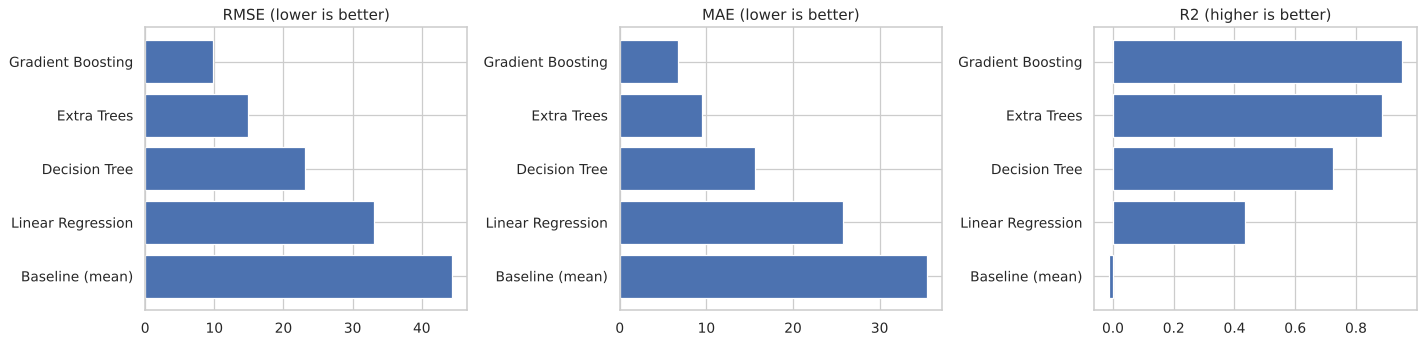

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, metric, title in zip(
    axes,
    ["RMSE", "MAE", "R2"],
    ["RMSE (lower is better)", "MAE (lower is better)", "R2 (higher is better)"],
):
    ax.barh(results["model"], results[metric])
    ax.set_title(title)
    ax.invert_yaxis()

plt.tight_layout()
plt.show()

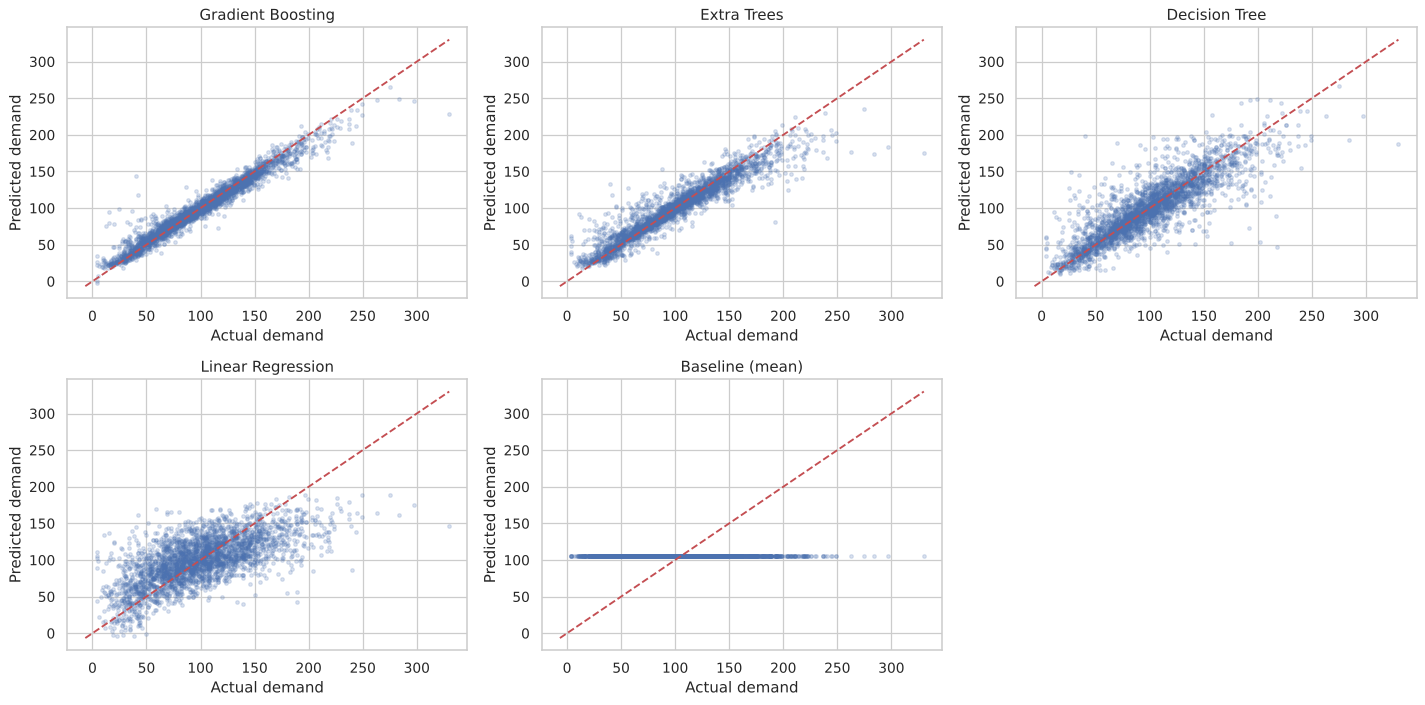

In [9]:
rng = np.random.default_rng(42)
idx = rng.choice(len(y_test), size=3000, replace=False)

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
lower = min(float(y_test.min()), min(float(np.min(p)) for p in predictions.values()))
upper = max(float(y_test.max()), max(float(np.max(p)) for p in predictions.values()))

for ax, name in zip(axes.flat, results["model"]):
    ax.scatter(y_test.values[idx], predictions[name][idx], alpha=0.2, s=8)
    ax.plot([lower, upper], [lower, upper], "r--")
    ax.set_title(name)
    ax.set_xlabel("Actual demand")
    ax.set_ylabel("Predicted demand")

for ax in axes.flat[len(results):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

Mean residual: -0.18


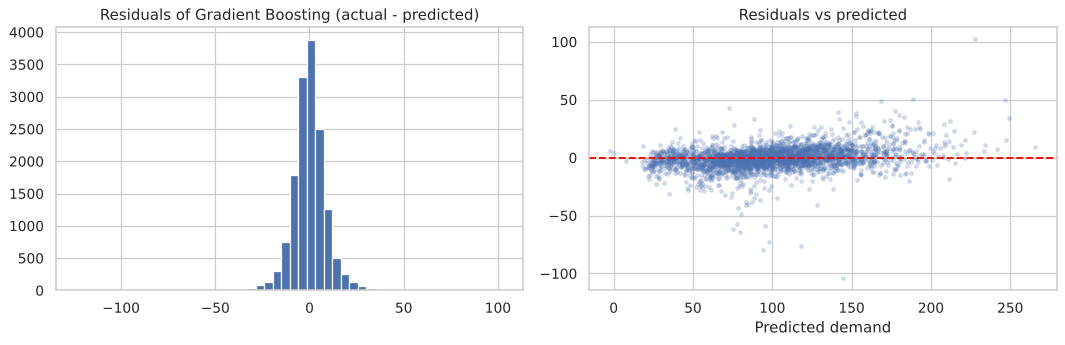

In [10]:
pred = predictions[best_name]
residuals = y_test.values - pred

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(residuals, bins=50)
axes[0].set_title("Residuals of " + best_name + " (actual - predicted)")

axes[1].scatter(pred[idx], residuals[idx], alpha=0.2, s=8)
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_title("Residuals vs predicted")
axes[1].set_xlabel("Predicted demand")

plt.tight_layout()
plt.show()

print("Mean residual:", round(residuals.mean(), 2))

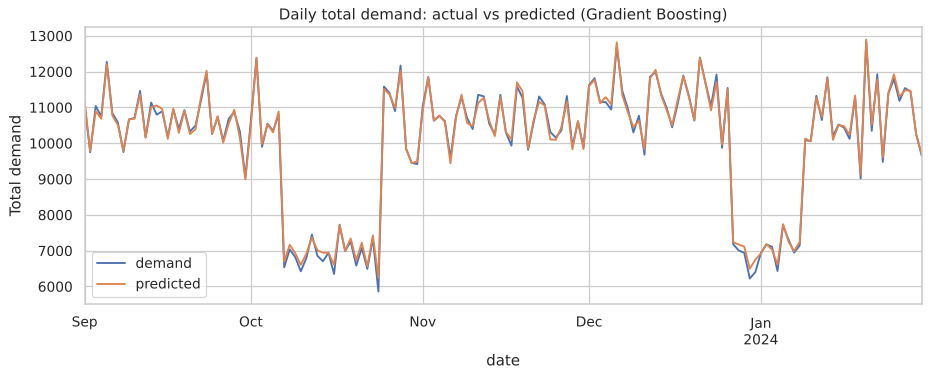

In [11]:
daily = test[["date", "demand"]].copy()
daily["predicted"] = pred
daily = daily.groupby("date").sum()

daily.plot(figsize=(12, 4), title="Daily total demand: actual vs predicted (" + best_name + ")")
plt.ylabel("Total demand")
plt.show()

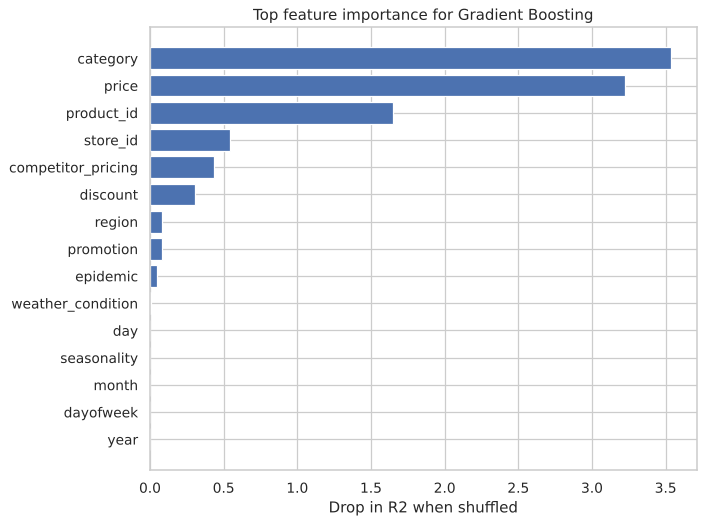

,feature,importance
2,category,3.5330
5,price,3.2271
1,product_id,1.6515
0,store_id,0.5454
9,competitor_pricing,0.4354
6,discount,0.3078
3,region,0.0799
8,promotion,0.0797
11,epidemic,0.0481
7,weather_condition,0.0045


In [12]:
sample = X_test.sample(min(500, len(X_test)), random_state=42)

importance = permutation_importance(
    best_model,
    sample,
    y_test.loc[sample.index],
    n_repeats=2,
    random_state=42,
    scoring="r2",
    n_jobs=-1,
)

importance_df = pd.DataFrame({
    "feature": sample.columns,
    "importance": importance.importances_mean,
}).sort_values("importance", ascending=False)

top_features = importance_df.head(15).sort_values("importance")

plt.figure(figsize=(8, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.title("Top feature importance for " + best_name)
plt.xlabel("Drop in R2 when shuffled")
plt.tight_layout()
plt.show()

importance_df.round(4)

In [13]:
errors = test[["category", "region", "epidemic", "promotion", "weather_condition"]].copy()
errors["abs_error"] = np.abs(residuals)

for col in ["category", "region", "epidemic", "promotion", "weather_condition"]:
    print(errors.groupby(col)["abs_error"].mean().round(2).to_string())
    print()

category
Clothing       6.61
Electronics    5.84
Furniture      4.12
Groceries      7.97
Toys           7.06

region
East     6.71
North    6.86
South    6.68
West     6.27

epidemic
0    6.45
1    7.55

promotion
0    5.87
1    8.33

weather_condition
Cloudy    6.57
Rainy     6.40
Snowy     6.35
Sunny     7.28



In [14]:
results.to_csv("model_comparison.csv", index=False)
joblib.dump(best_model, "best_model.joblib", compress=3)
print("Saved model_comparison.csv and best_model.joblib")
print("Best model:", best_name)

Saved model_comparison.csv and best_model.joblib
Best model: Gradient Boosting
